# 30-Day Hospital Readmission Risk for Diabetic Patients
**NextGen Institute · Machine Learning · Final Project (#12)**

## 1 · Problem framing
| | |
|---|---|
| **Who has the problem** | Hospitals and their care teams |
| **Decision supported** | At discharge, which patients deserve a follow-up call or visit |
| **Target** | `readmitted_30` = 1 if the patient returned in **less than 30 days**, else 0 |
| **Main metrics** | Recall, PR-AUC and ROC-AUC |
| **Why** | Missing a high-risk patient (false negative) costs more than one extra follow-up call (false positive). Accuracy is misleading because only about 11% of patients are readmitted within 30 days |

**Dataset:** Diabetes 130-US Hospitals (1999–2008), UCI: https://archive.ics.uci.edu/dataset/296

## 2 · Setup

In [19]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from scipy.stats import loguniform, randint

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (roc_auc_score, average_precision_score,
                             classification_report, ConfusionMatrixDisplay)
from sklearn.model_selection import (GroupShuffleSplit, StratifiedGroupKFold,
                                     cross_validate, cross_val_predict,
                                     RandomizedSearchCV)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

pd.set_option("display.max_columns", 60)
RANDOM_STATE = 42

# Set to True to re-run the hyperparameter search (about 25+ minutes on Colab).
# False reuses the best parameters found in the original run.
RUN_SEARCH = False

## 3 · Data understanding
Upload `diabetic_data.csv` to Colab first (Files panel → Upload). In this dataset `"?"` means missing, while `"None"` (for example in `A1Cresult`) means *the test was not done*, which is real information, so we keep it.

In [20]:
df = pd.read_csv("diabetic_data.csv", na_values="?", keep_default_na=False)

# Make sure the numeric columns are really numeric (some pandas versions read them as text)
NUMERIC_COLS = ["admission_type_id", "discharge_disposition_id", "admission_source_id",
                "time_in_hospital", "num_lab_procedures", "num_procedures",
                "num_medications", "number_outpatient", "number_emergency",
                "number_inpatient", "number_diagnoses", "patient_nbr"]
df[NUMERIC_COLS] = df[NUMERIC_COLS].apply(pd.to_numeric)

print("shape:", df.shape)
df.head()

shape: (101766, 50)


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,payer_code,medical_specialty,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,diag_1,diag_2,diag_3,number_diagnoses,max_glu_serum,A1Cresult,metformin,repaglinide,nateglinide,chlorpropamide,glimepiride,acetohexamide,glipizide,glyburide,tolbutamide,pioglitazone,rosiglitazone,acarbose,miglitol,troglitazone,tolazamide,examide,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),NaN,6,25,1,1,NaN,Pediatrics-Endocrinology,41,0,1,0,0,0,250.83,NaN,NaN,1,None,None,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),NaN,1,1,7,3,NaN,NaN,59,0,18,0,0,0,276,250.01,255,9,None,None,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),NaN,1,1,7,2,NaN,NaN,11,5,13,2,0,1,648,250,V27,6,None,None,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),NaN,1,1,7,2,NaN,NaN,44,1,16,0,0,0,8,250.43,403,7,None,None,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),NaN,1,1,7,1,NaN,NaN,51,0,8,0,0,0,197,157,250,5,None,None,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,Steady,No,No,No,No,No,Ch,Yes,NO


In [21]:
print(df["readmitted"].value_counts())

# Target: readmitted in less than 30 days
df["readmitted_30"] = (df["readmitted"] == "<30").astype(int)
print("\n", df["readmitted_30"].value_counts(normalize=True).round(4))

print("\nColumn types:\n", df.dtypes.value_counts())

missing = df.isna().mean().sort_values(ascending=False)
print("\nMissing values:\n", missing[missing > 0].round(4))

print("\nDuplicate rows:", df.duplicated().sum())
print("Unique patients:", df["patient_nbr"].nunique(), "of", len(df))

readmitted
NO     54864
>30    35545
<30    11357
Name: count, dtype: int64

 readmitted_30
0    0.8884
1    0.1116
Name: proportion, dtype: float64

Column types:
 object    37
int64     14
Name: count, dtype: int64

Missing values:
 weight               0.9686
medical_specialty    0.4908
payer_code           0.3956
race                 0.0223
diag_3               0.0140
diag_2               0.0035
diag_1               0.0002
dtype: float64

Duplicate rows: 0
Unique patients: 71518 of 101766


**What we learn**
- The target is imbalanced (about 11% positives), so a model that always says "no readmission" gets about 89% accuracy and 0% recall. This is our **baseline**.
- `weight` is almost entirely missing, so we drop it.
- `medical_specialty` and `payer_code` have a lot of missing values, so we keep them as a separate "Missing" category.
- Many rows belong to the same patient (`patient_nbr`), so we must split **by patient** to avoid leakage.

## 4 · Initial cleaning
Only dropping columns and rows (no statistics are learned from the data), so this is safe before the split.
Patients who died or went to hospice cannot be readmitted, so they are removed.

In [22]:
df = df.drop(columns=["weight", "encounter_id"])

# Discharge codes: 11 Expired, 13/14 Hospice, 19/20/21 Expired in other settings
dead_or_hospice = [11, 13, 14, 19, 20, 21]
print("Before:", len(df))
df = df[~df["discharge_disposition_id"].isin(dead_or_hospice)].copy()
print("After :", len(df), "(expected: fewer rows than before)")
print("Readmission rate:", round(df["readmitted_30"].mean(), 4))

Before: 101766
After : 99343 (expected: fewer rows than before)
Readmission rate: 0.1139


## 5 · Train / test split (grouped by patient)

In [23]:
X = df.drop(columns=["readmitted", "readmitted_30"])
y = df["readmitted_30"]
groups = df["patient_nbr"]

gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_STATE)
train_idx, test_idx = next(gss.split(X, y, groups))

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

print("train:", X_train.shape, "| test:", X_test.shape)
print("target rate  train:", y_train.mean().round(4), "| test:", y_test.mean().round(4))
overlap = set(X_train["patient_nbr"]) & set(X_test["patient_nbr"])
print("patients in both sets:", len(overlap))

train: (79541, 47) | test: (19802, 47)
target rate  train: 0.1144 | test: 0.1119
patients in both sets: 0


The test set is **not touched again** until the final evaluation. All EDA below uses the training set only.

## 6 · Exploratory data analysis (training set only)

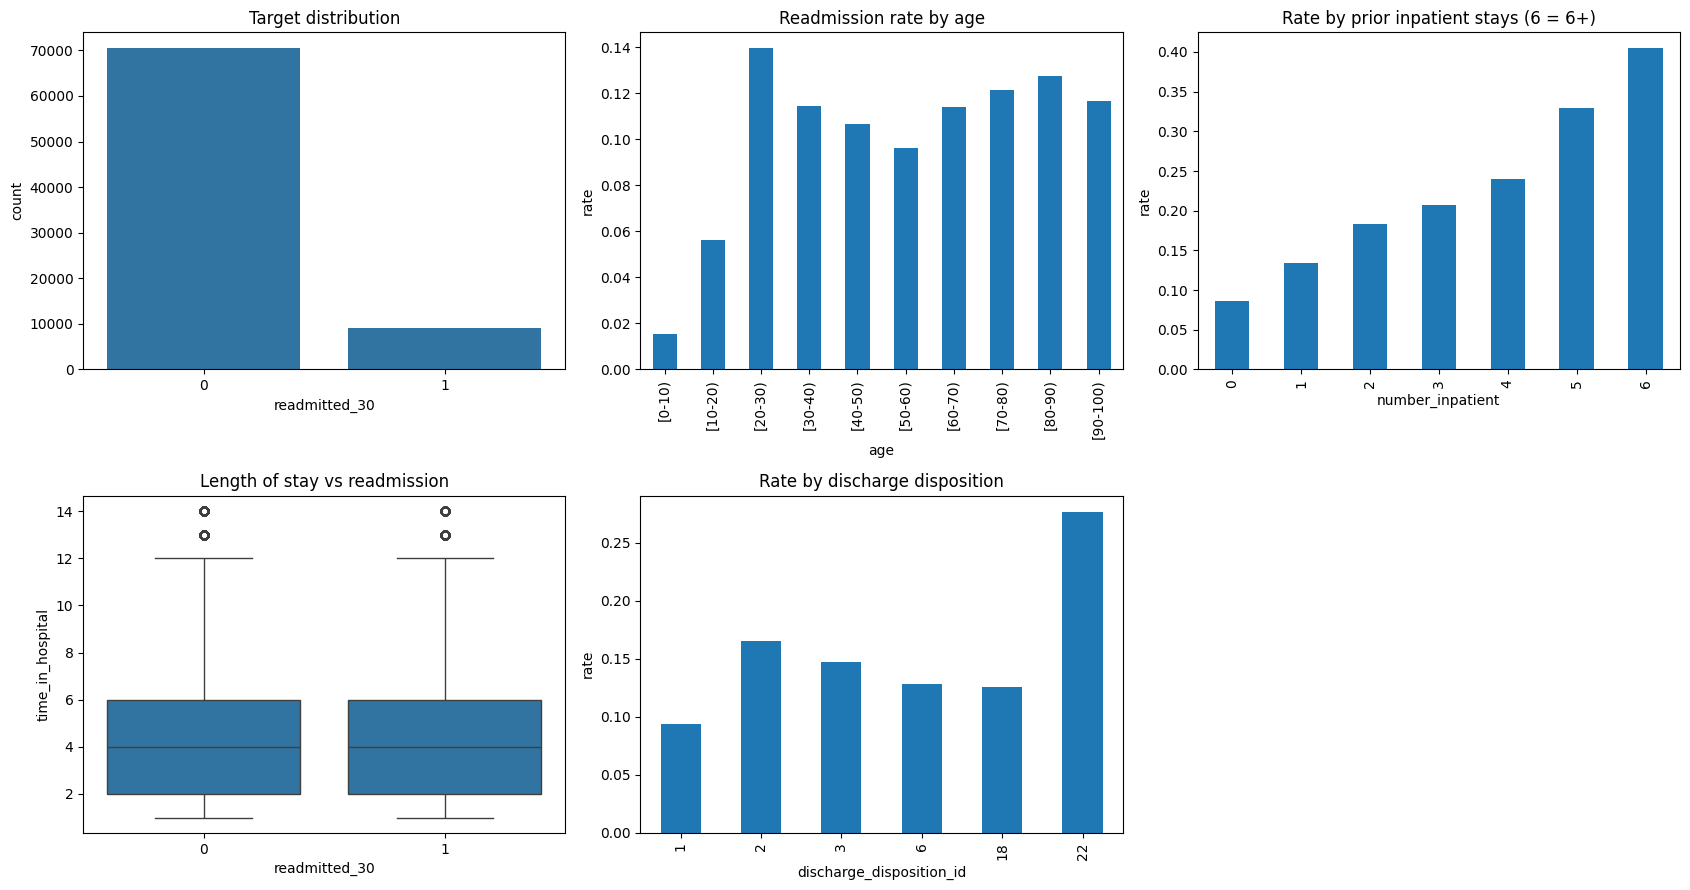

In [24]:
train = X_train.copy()
train["readmitted_30"] = y_train.values

fig, axes = plt.subplots(2, 3, figsize=(17, 9))

sns.countplot(x="readmitted_30", data=train, ax=axes[0, 0])
axes[0, 0].set_title("Target distribution")

train.groupby("age")["readmitted_30"].mean().plot(kind="bar", ax=axes[0, 1],
                                                   title="Readmission rate by age")
axes[0, 1].set_ylabel("rate")

train.groupby(train["number_inpatient"].clip(upper=6))["readmitted_30"].mean().plot(
    kind="bar", ax=axes[0, 2], title="Rate by prior inpatient stays (6 = 6+)")
axes[0, 2].set_ylabel("rate")

sns.boxplot(x="readmitted_30", y="time_in_hospital", data=train, ax=axes[1, 0])
axes[1, 0].set_title("Length of stay vs readmission")

top = train["discharge_disposition_id"].value_counts().head(6).index
(train[train["discharge_disposition_id"].isin(top)]
 .groupby("discharge_disposition_id")["readmitted_30"].mean()
 .plot(kind="bar", ax=axes[1, 1], title="Rate by discharge disposition"))
axes[1, 1].set_ylabel("rate")

axes[1, 2].axis("off")
plt.tight_layout()
plt.show()

In [25]:
# Categorical cardinality and near-constant drug columns
cat_cols_raw = train.select_dtypes(include="object").columns
print(train[cat_cols_raw].nunique().sort_values(ascending=False).head(12))

DRUG_COLS = ["metformin","repaglinide","nateglinide","chlorpropamide","glimepiride",
             "acetohexamide","glipizide","glyburide","tolbutamide","pioglitazone",
             "rosiglitazone","acarbose","miglitol","troglitazone","tolazamide",
             "examide","citoglipton","insulin","glyburide-metformin",
             "glipizide-metformin","glimepiride-pioglitazone",
             "metformin-rosiglitazone","metformin-pioglitazone"]

print("\nShare of the most common value in each drug column:")
for c in DRUG_COLS:
    print(f"{c:28s} {train[c].value_counts(normalize=True).iloc[0]:.3f}")

print()
print(train["age"].value_counts().sort_index())

diag_3                 760
diag_2                 718
diag_1                 700
medical_specialty       72
payer_code              17
age                     10
race                     5
glyburide-metformin      4
max_glu_serum            4
A1Cresult                4
metformin                4
repaglinide              4
dtype: int64

Share of the most common value in each drug column:
metformin                    0.799
repaglinide                  0.984
nateglinide                  0.993
chlorpropamide               0.999
glimepiride                  0.948
acetohexamide                1.000
glipizide                    0.874
glyburide                    0.895
tolbutamide                  1.000
pioglitazone                 0.927
rosiglitazone                0.936
acarbose                     0.997
miglitol                     1.000
troglitazone                 1.000
tolazamide                   1.000
examide                      1.000
citoglipton                  1.000
insulin        

### Key insights
1. **Prior inpatient stays** (`number_inpatient`) is the strongest signal: the readmission rate rises steadily from roughly 8–9% with no prior stays to about 40% with 6 or more.
2. **Discharge destination matters:** patients sent home have the lowest rate (about 9–10%), while those transferred to rehabilitation (code 22) have the highest (about 28%).
3. **Length of stay alone does not separate** readmitted from non-readmitted patients (the boxplots are almost identical).
4. **Age is not linear:** very young patients are rarely readmitted, and from about age 20 the rate stays roughly flat at 10–13%. The youngest groups are very small (only 131 training patients aged 0–10 and 552 aged 10–20), so their rates are not stable.
5. **Most drug columns are almost constant** (more than 99% one value). Only insulin and metformin show real variation.

## 7 · Feature engineering and preprocessing pipeline
- Row-wise feature creation (`add_features`) learns nothing from the data, so it can be applied to train and test directly.
- Everything that **learns** from data (median, scaling, category lists) lives inside the scikit-learn `Pipeline` and is fitted on the training set only.
- ICD-9 diagnosis codes (about 700 unique values) are grouped into broad medical categories.

In [26]:
def icd_group(code):
    if pd.isna(code):
        return "Missing"
    c = str(code)
    if c.startswith(("V", "E")):
        return "Other"
    try:
        n = float(c)
    except ValueError:
        return "Other"
    i = int(n)
    if 390 <= n < 460 or i == 785: return "Circulatory"
    if 460 <= n < 520 or i == 786: return "Respiratory"
    if 520 <= n < 580 or i == 787: return "Digestive"
    if i == 250:                   return "Diabetes"
    if 800 <= n < 1000:            return "Injury"
    if 710 <= n < 740:             return "Musculoskeletal"
    if 580 <= n < 630 or i == 788: return "Genitourinary"
    if 140 <= n < 240:             return "Neoplasms"
    return "Other"

age_map = {f"[{i}-{i+10})": i + 5 for i in range(0, 100, 10)}

# Near-constant drug columns, decided from the TRAINING set only
near_const = [c for c in DRUG_COLS
              if X_train[c].value_counts(normalize=True).iloc[0] > 0.99]
print("Dropping", len(near_const), "near-constant drug columns")

def add_features(d):
    d = d.copy()
    d["age_num"] = d["age"].map(age_map)
    for c in ["diag_1", "diag_2", "diag_3"]:
        d[c] = d[c].apply(icd_group)
    d["total_prior_visits"] = d["number_outpatient"] + d["number_emergency"] + d["number_inpatient"]
    d["n_drugs_taken"] = (d[DRUG_COLS] != "No").sum(axis=1)
    d["n_drugs_changed"] = d[DRUG_COLS].isin(["Up", "Down"]).sum(axis=1)
    # these are category codes, not quantities
    for c in ["admission_type_id", "discharge_disposition_id", "admission_source_id"]:
        d[c] = d[c].astype(str)
    return d.drop(columns=near_const)

groups_train = X_train["patient_nbr"].values      # kept for grouped cross-validation
X_tr = add_features(X_train).drop(columns=["patient_nbr"])
X_te = add_features(X_test).drop(columns=["patient_nbr"])

num_cols = X_tr.select_dtypes(include="number").columns.tolist()
cat_cols = X_tr.select_dtypes(include="object").columns.tolist()
print("numeric:", len(num_cols), "| categorical:", len(cat_cols))
print(X_tr["diag_1"].value_counts())

Dropping 15 near-constant drug columns
numeric: 12 | categorical: 23
diag_1
Circulatory        23739
Other              14182
Respiratory        11225
Digestive           7487
Diabetes            6930
Injury              5475
Genitourinary       4000
Musculoskeletal     3972
Neoplasms           2516
Missing               15
Name: count, dtype: int64


In [27]:
num_pipe = Pipeline([
    ("imp", SimpleImputer(strategy="median")),
    ("sc", StandardScaler()),
])
cat_pipe = Pipeline([
    ("imp", SimpleImputer(strategy="constant", fill_value="Missing")),
    ("oh", OneHotEncoder(handle_unknown="infrequent_if_exist",
                         min_frequency=50, sparse_output=False)),
])
preprocess = ColumnTransformer([
    ("num", num_pipe, num_cols),
    ("cat", cat_pipe, cat_cols),
])

# Quick check: fit on train only, transform both
Xt_tr = preprocess.fit_transform(X_tr)
Xt_te = preprocess.transform(X_te)
print("train matrix:", Xt_tr.shape, "| test matrix:", Xt_te.shape)

train matrix: (79541, 189) | test matrix: (19802, 189)


## 8 · Baseline and model comparison
Models: a majority-class baseline plus Logistic Regression, Random Forest and Hist Gradient Boosting.
Cross-validation is **grouped by patient** (`StratifiedGroupKFold`) so the same patient never appears in both the training and validation folds.

In [28]:
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

models = {
    "Baseline (majority)": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "Random Forest": RandomForestClassifier(
        n_estimators=200, min_samples_leaf=20, class_weight="balanced_subsample",
        n_jobs=-1, random_state=RANDOM_STATE),
    "Hist Gradient Boosting": HistGradientBoostingClassifier(
        class_weight="balanced", random_state=RANDOM_STATE),
}
scoring = {"roc_auc": "roc_auc", "pr_auc": "average_precision",
           "recall": "recall", "precision": "precision"}

results = []
for name, model in models.items():
    pipe = Pipeline([("prep", clone(preprocess)), ("model", model)])
    s = cross_validate(pipe, X_tr, y_train, cv=cv, groups=groups_train,
                       scoring=scoring, n_jobs=1, error_score=np.nan)
    results.append({"model": name,
                    "ROC-AUC": np.nanmean(s["test_roc_auc"]),
                    "PR-AUC": np.nanmean(s["test_pr_auc"]),
                    "Recall": np.nanmean(s["test_recall"]),
                    "Precision": np.nanmean(s["test_precision"])})
    print(name, "done")

comparison = pd.DataFrame(results).set_index("model").round(3)
comparison

Baseline (majority) done
Logistic Regression done
Random Forest done
Hist Gradient Boosting done


,ROC-AUC,PR-AUC,Recall,Precision
model,,,,
Baseline (majority),0.500,0.114,0.000,0.000
Logistic Regression,0.663,0.215,0.550,0.183
Random Forest,0.671,0.216,0.427,0.212
Hist Gradient Boosting,0.669,0.226,0.565,0.184


The three models are close to each other and clearly better than the baseline. The best models reach a ROC-AUC of about 0.67 on this hard task. We continue with **Hist Gradient Boosting**, which has the best PR-AUC and recall.
(The precision warnings come from the baseline, which never predicts the positive class.)

## 9 · Hyperparameter tuning (training data only)
We tune on **PR-AUC** (`average_precision`) because it suits imbalanced data and does not depend on a threshold.

In [29]:
pipe_hgb = Pipeline([
    ("prep", clone(preprocess)),
    ("model", HistGradientBoostingClassifier(class_weight="balanced",
                                             random_state=RANDOM_STATE)),
])

if RUN_SEARCH:
    param_dist = {
        "model__learning_rate": loguniform(0.01, 0.2),
        "model__max_iter": randint(100, 400),
        "model__max_leaf_nodes": randint(8, 64),
        "model__min_samples_leaf": randint(20, 200),
        "model__l2_regularization": loguniform(1e-3, 10),
    }
    search = RandomizedSearchCV(pipe_hgb, param_distributions=param_dist, n_iter=20,
                                scoring="average_precision", cv=cv, n_jobs=1,
                                random_state=RANDOM_STATE, verbose=1)
    search.fit(X_tr, y_train, groups=groups_train)
    print("Best CV PR-AUC:", round(search.best_score_, 4))
    best_model = search.best_estimator_
    print(search.best_params_)
else:
    # Best parameters found by the search (CV PR-AUC = 0.2274)
    best_params = {
        "model__l2_regularization": 7.261414516028836,
        "model__learning_rate": 0.06162682089644249,
        "model__max_iter": 140,
        "model__max_leaf_nodes": 36,
        "model__min_samples_leaf": 34,
    }
    best_model = clone(pipe_hgb).set_params(**best_params)
    best_model.fit(X_tr, y_train)
    print("Fitted with the saved best parameters:", best_params)

Fitted with the saved best parameters: {'model__l2_regularization': 7.261414516028836, 'model__learning_rate': 0.06162682089644249, 'model__max_iter': 140, 'model__max_leaf_nodes': 36, 'model__min_samples_leaf': 34}


Tuning improved the CV PR-AUC only slightly (about 0.226 to 0.227): the limit comes from the information in the data, not the model settings.

## 10 · Choosing the decision thresholds
Thresholds are chosen from **out-of-fold predictions on the training set**, never from the test set.
We use three risk tiers instead of a single cut-off, so a care team can match its follow-up to its capacity.

In [30]:
oof_proba = cross_val_predict(clone(best_model), X_tr, y_train, cv=cv,
                              groups=groups_train, method="predict_proba", n_jobs=1)[:, 1]

rows = []
for t in [0.30, 0.40, 0.45, 0.50, 0.55, 0.60, 0.65, 0.70]:
    pred = oof_proba >= t
    tp = (pred & (y_train.values == 1)).sum()
    rows.append({"threshold": t,
                 "recall": tp / y_train.sum(),
                 "precision": tp / max(pred.sum(), 1),
                 "flagged_%": pred.mean() * 100})
pd.DataFrame(rows).round(3)

,threshold,recall,precision,flagged_%
0,0.30,0.941,0.128,84.362
1,0.40,0.799,0.149,61.546
2,0.45,0.694,0.164,48.463
3,0.50,0.568,0.184,35.252
4,0.55,0.444,0.211,24.048
5,0.60,0.335,0.237,16.177
6,0.65,0.219,0.279,8.943
7,0.70,0.128,0.339,4.322


In [31]:
THRESHOLD_MED, THRESHOLD_HIGH = 0.45, 0.60

## 11 · Final evaluation on the untouched test set

Test ROC-AUC: 0.6727
Test PR-AUC : 0.2313
Baseline PR-AUC (= prevalence): 0.1119

              precision    recall  f1-score   support

           0      0.933     0.549     0.692     17586
           1      0.162     0.689     0.262      2216

    accuracy                          0.565     19802
   macro avg      0.547     0.619     0.477     19802
weighted avg      0.847     0.565     0.643     19802



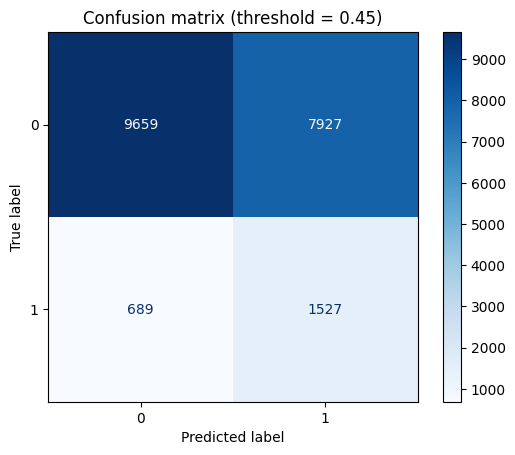

In [32]:
test_proba = best_model.predict_proba(X_te)[:, 1]
test_pred = (test_proba >= THRESHOLD_MED).astype(int)

print("Test ROC-AUC:", round(roc_auc_score(y_test, test_proba), 4))
print("Test PR-AUC :", round(average_precision_score(y_test, test_proba), 4))
print("Baseline PR-AUC (= prevalence):", round(y_test.mean(), 4))
print()
print(classification_report(y_test, test_pred, digits=3))

ConfusionMatrixDisplay.from_predictions(y_test, test_pred, cmap="Blues")
plt.title(f"Confusion matrix (threshold = {THRESHOLD_MED})")
plt.show()

In [33]:
tier = np.where(test_proba >= THRESHOLD_HIGH, "High",
        np.where(test_proba >= THRESHOLD_MED, "Medium", "Low"))
summary = (pd.DataFrame({"tier": tier, "y": y_test.values})
           .groupby("tier")["y"].agg(patients="size", readmitted="sum", rate="mean"))
summary["% of patients"] = summary["patients"] / len(y_test) * 100
summary["% of all readmissions"] = summary["readmitted"] / y_test.sum() * 100
summary.loc[["High", "Medium", "Low"]].round(3)

,patients,readmitted,rate,% of patients,% of all readmissions
tier,,,,,
High,3262,777,0.238,16.473,35.063
Medium,6192,750,0.121,31.270,33.845
Low,10348,689,0.067,52.257,31.092


## 12 · Error analysis and feature importance

In [34]:
err = X_te.copy()
err["y"] = y_test.values
err["pred"] = test_pred

def recall_by(col, min_n=100):
    g = err[err["y"] == 1].groupby(col)["pred"].agg(["mean", "size"])
    return g[g["size"] >= min_n].rename(columns={"mean": "recall", "size": "n_positives"}).round(3)

print(recall_by("age"))
print()
print(recall_by("discharge_disposition_id"))

         recall  n_positives
age                         
[40-50)   0.564          202
[50-60)   0.615          356
[60-70)   0.623          464
[70-80)   0.751          587
[80-90)   0.800          390

                          recall  n_positives
discharge_disposition_id                     
1                          0.499         1081
22                         1.000          113
3                          0.909          394
6                          0.818          319


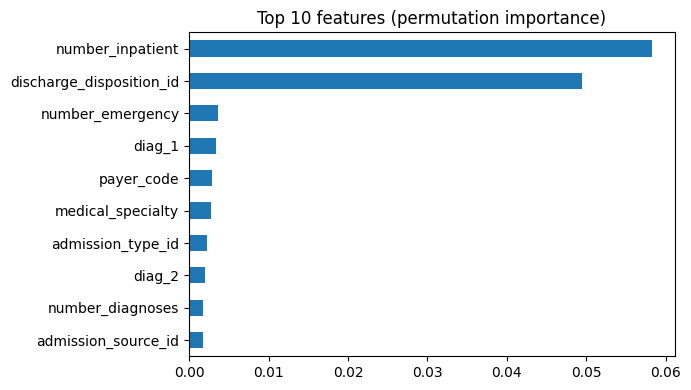

,0
number_inpatient,0.0582
discharge_disposition_id,0.0495
number_emergency,0.0036
diag_1,0.0034
payer_code,0.0029
medical_specialty,0.0027
admission_type_id,0.0023
diag_2,0.0020
number_diagnoses,0.0018
admission_source_id,0.0017


In [35]:
sample = X_te.sample(5000, random_state=RANDOM_STATE)
pi = permutation_importance(best_model, sample, y_test.loc[sample.index],
                            scoring="average_precision", n_repeats=3,
                            random_state=RANDOM_STATE, n_jobs=1)
imp = pd.Series(pi.importances_mean, index=X_te.columns).sort_values(ascending=False)

imp.head(10).sort_values().plot(kind="barh", figsize=(7, 4),
                                title="Top 10 features (permutation importance)")
plt.tight_layout()
plt.show()
imp.head(10).round(4)

## 13 · Business insight and limitations
**What the model does.** At discharge it sorts diabetic patients into three risk tiers. In our test set, patients in the **High** tier were readmitted much more often than those in the **Low** tier (see the table in section 11).

**What the hospital should do.**
- High tier: follow-up call plus a post-discharge visit.
- Medium tier: follow-up phone call.
- Low tier: standard care.

Following up High and Medium patients catches roughly two thirds of readmissions while contacting about half of the patients (see the classification report for the exact recall).

**Limitations**
- The model still misses roughly a third of readmissions, so it must support, not replace, clinical judgment.
- It is weakest for patients discharged **home**, who make up about half of all readmissions.
- Recall is lower for younger adults (about 56%) than for patients aged 80–90 (about 80%).
- Data comes from US hospitals between 1999 and 2008, and it may not reflect current practice or other health systems.
- Scores rank patients by risk; because we used class weights, they are not literal probabilities.

## 14 · Save the final pipeline for the web app

In [36]:
defaults = {}
for c in X_train.columns:
    if c == "patient_nbr":
        continue
    if X_train[c].dtype == "object":
        defaults[c] = None if c in ["medical_specialty", "payer_code"] else X_train[c].mode()[0]
    else:
        v = float(X_train[c].median())
        defaults[c] = int(v) if v.is_integer() else v

import sklearn
print("scikit-learn==" + sklearn.__version__)

joblib.dump({"pipeline": best_model,
             "threshold_medium": THRESHOLD_MED,
             "threshold_high": THRESHOLD_HIGH,
             "near_const": near_const,
             "age_map": age_map,
             "defaults": defaults}, "readmission_model.joblib")
print("saved readmission_model.joblib")

scikit-learn==1.6.1
saved readmission_model.joblib
